# Microbiome-Based Disease Prediction: DeepPhylo vs. Random Forest

This notebook benchmarks a phylogeny-aware deep-learning model (**DeepPhylo**) against a
standard **Random Forest** baseline for predicting disease status from 16S microbiome
abundance profiles. It is organised into two independent analyses:

1. **Oral disease classification (Leave-One-Study-Out).** Using pooled oral samples from many
   public studies, we predict each disease vs. healthy controls (HC), always holding out one
   *entire study* for testing. This measures how well a model generalises **across studies**
   (different labs, protocols, and batch effects).

2. **Paired oral–gut projects (within-study 5-fold CV).** Using studies that sampled both oral
   and gut sites from the same cohorts, we predict disease vs. HC separately for each body site
   with stratified cross-validation, so we can compare how predictive each site is.

For both analyses, DeepPhylo and Random Forest are run on **identical data splits** and their
per-split AUC is compared.

> **Environment note.** The code expects a local `DeepPhylo` package, the microbiome `.biom`
> tables and metadata files, and a precomputed phylogenetic embedding on disk. The paths are
> specific to the original machine and would need to be adjusted to re-run elsewhere.

# Methods

## Microbiome datasets and study cohorts

Disease status was predicted from 16S rRNA gene amplicon microbiome profiles
assembled from multiple publicly available studies. Two complementary
collections were analysed. The first was a pooled **oral** collection, in which
samples from many independent studies were aggregated to enable cross-study
evaluation of disease-versus-healthy-control (HC) classification. The second was
a set of **paired oral–gut** projects, in which the oral and gut microbiota were
sampled from the same cohorts, allowing a within-study comparison of the
predictive value of each body site. For each collection, feature tables were
stored as BIOM-format operational taxonomic unit (OTU) count matrices with
accompanying sample metadata (body site, disease status, and study/BioProject
identifier).

## Quality control and feature filtering

Identical quality-control (QC) criteria were applied to both collections. First,
the feature table was restricted to samples present in the metadata, and empty
features and samples were removed. Rare OTUs, defined as those detected in 50 or
fewer samples, were discarded to reduce noise and dimensionality. Samples with a
sequencing depth below 1,000 total reads were removed as unreliable. After each
filtering step the table was re-checked for empty rows and columns, and the
metadata were re-synchronised to the surviving samples. Samples with a missing
disease label or a non-specific "Other" label were excluded so that every
retained sample carried a well-defined disease or HC status. Finally, per-sample
relative abundances were obtained by total-sum normalisation of the filtered
count table, and the resulting abundance matrix was aligned to a fixed,
phylogenetically ordered set of OTUs (see below).

## Phylogenetic feature representation

DeepPhylo exploits the evolutionary relationships among taxa. A cophenetic
(patristic) distance matrix encoding the pairwise phylogenetic tree distances
between OTUs was used to derive a phylogeny-informed taxa embedding. OTUs were
arranged in a fixed phylogenetic order so that evolutionarily related taxa occupy
neighbouring positions, allowing the abundance profile of each sample to be
treated as a one-dimensional signal. Both the ordered OTU list and the
precomputed phylogenetic embedding were shared across all experiments to ensure
that every model and data split used an identical feature representation.

## DeepPhylo model and training

The phylogeny-aware classifier (DeepPhylo) applies one-dimensional convolutional
filters across the phylogenetically ordered OTUs, so that each filter integrates
information from neighbouring (evolutionarily related) taxa. The network used a
hidden dimension of 80, a convolutional kernel of size 3, and a pooling kernel of
size 7, with rectified linear unit (ReLU) activations, and produced a single
sigmoid output representing the predicted disease probability.

Models were trained by minimising the binary cross-entropy loss using the AdamW
optimiser with a learning rate of 1×10⁻³ and a batch size of 32, for up to 100
epochs. Within every training set, 15% of the samples were held out as an
internal validation set, and early stopping was applied with a patience of 10
epochs; the weights from the epoch with the lowest validation loss were retained
for prediction. When class sizes permitted, the internal train/validation split
was stratified by label. A fixed random seed was used throughout to promote
reproducibility, and all models were trained on GPU when available.

## Random Forest baseline

As a baseline, a Random Forest classifier was trained on the same relative
abundance features. It comprised 100 trees with balanced class weights to
mitigate class imbalance, and used a fixed random seed. Critically, the Random
Forest and DeepPhylo models were trained and evaluated on **identical data
splits** in every experiment, so that their per-split performance is directly
comparable. Predicted disease probabilities were taken from the positive-class
output of the fitted forest.

## Evaluation design 1: cross-study generalisation (leave-one-study-out)

Cross-study generalisation was assessed on the oral collection using a
leave-one-study-out (LOSO) scheme, applied separately to each oral site
(saliva, tooth, tongue, and oral mucosa). Within each site, studies and diseases
were selected according to three criteria: (i) a study was retained only if it
contained both HC samples and at least one disease group; (ii) a study was
required to include more than 10 HC samples so that the control group was not
negligibly small; and (iii) a disease was analysed only if it was present in at
least two studies, which is the minimum required for LOSO (one study to train on
and one to hold out).

For each qualifying disease, every study was in turn held out entirely as the
test set while the model was trained on the remaining studies, framing the task
as the target disease versus HC. Because the held-out study contributes its own
laboratory- and protocol-specific batch effects, this design provides a strict
test of generalisation to unseen studies. Splits in which either the training or
test partition lacked both classes—for which the area under the receiver
operating characteristic curve (AUC) is undefined—were skipped. The test AUC was
recorded for every evaluable study, and results were aggregated per disease and
per site.

## Evaluation design 2: within-study cross-validation (paired oral–gut)

The paired oral–gut collection was used to compare the predictive value of the
oral and gut microbiomes within the same cohorts. Samples were grouped by
(project × body site × disease status), and only groups containing more than 10
samples were retained. A project was evaluated only if it contained all four
expected groups—both body sites, each with HC and disease samples—so that the
oral-versus-gut comparison was always made on the same cohort.

For each qualifying project, the task was defined as disease (any non-HC status)
versus HC and was evaluated **separately** for the gut and oral samples using
stratified five-fold cross-validation. Within each training fold, an internal
validation split (15%) was used for early stopping of DeepPhylo, exactly as in
the LOSO analysis. Projects or sites whose smaller class contained fewer samples
than the number of folds were skipped, as were individual folds whose test
partition did not contain both classes. Per-fold test AUC was recorded, and a
per-(project × site) summary (mean and standard deviation across folds) was
computed.

## Performance evaluation and model comparison

Classification performance was quantified throughout by the AUC, computed from
the predicted disease probabilities on each held-out partition. Because DeepPhylo
and Random Forest were evaluated on identical splits within both designs, the two
models could be compared directly at the level of the individual test study
(LOSO) or the individual fold, study, and body site (five-fold cross-validation),
with an AUC of 0.5 denoting chance-level performance. For the paired oral–gut
analysis, each project was additionally annotated with its associated disease
(the single non-HC status present in the project) to enable disease-level
comparison. Results were visualised as per-site and per-disease comparisons of
DeepPhylo versus Random Forest AUC, with paired points connected across models to
highlight per-study differences.

In [1]:
import sys
sys.path.insert(0, '/home/dongbiao/software/DeepPhylo')

import matplotlib as mpl
import os
import math
import biom
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from skbio import TreeNode

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

In [2]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

from deepphylo.pre_dataset import set_seed, reducer, DeepPhyDataset
from deepphylo.model import DeepPhylo_classification

set_seed(1234)

## Configuration and hyperparameters

All DeepPhylo settings live in one place so the rest of the notebook stays clean:

- **Model shape** — `DP_HIDDEN_SIZE`, a 1-D convolution kernel (`DP_KERNEL_CONV`) and a pooling
  kernel (`DP_KERNEL_POOL`). DeepPhylo treats the phylogenetically-ordered OTUs like a 1-D
  signal and slides filters over neighbouring (evolutionarily related) taxa.
- **Optimisation** — AdamW with learning rate `DP_LR`, batch size `DP_BATCH_SIZE`, up to
  `DP_EPOCHS` epochs, with **early stopping** after `DP_PATIENCE` epochs of no improvement.
  A fraction `DP_VAL_FRAC` of the training data is reserved as an internal validation set.

We also create the output directory and load the **cophenetic distance matrix** — the pairwise
patristic (tree) distances between OTUs — which encodes the phylogeny DeepPhylo uses to build
its taxa embedding.

In [5]:
DEVICE         = 'cuda' if torch.cuda.is_available() else 'cpu'
DP_HIDDEN_SIZE = 80
DP_KERNEL_CONV = 3
DP_KERNEL_POOL = 7
DP_LR          = 1e-3
DP_BATCH_SIZE  = 32
DP_ACTIVATION  = nn.ReLU()
DP_EPOCHS      = 100
DP_PATIENCE    = 10
DP_VAL_FRAC    = 0.15
print(f"Device: {DEVICE}")

OUTPUT_DIR = "../../data/disease_classification/leave_one_study_out"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Cophenetic distance matrix C (OTU x OTU), index = feature ids matching the biom table
C_full = pd.read_csv("../age_prediction/cophenetic_matrix.csv", index_col=0)
C_full.columns = C_full.index  # ensure square alignment

Device: cuda


## Training helpers

Two small utilities used throughout the notebook:

- **`train_deepphylo(...)`** — trains one binary DeepPhylo classifier. It wraps the abundance
  matrix and phylogenetic embedding in a `DeepPhyDataset`, trains with binary cross-entropy on
  the sigmoid output, and keeps the weights from the epoch with the lowest validation loss
  (early stopping).
- **`predict_proba(...)`** — runs a trained model in evaluation mode and returns the predicted
  disease probability for each test sample (used to compute AUC).

In [6]:
def train_deepphylo(X_tr, Y_tr, X_val, Y_val, phy_emb):
    """Train one binary DeepPhylo classifier with early stopping; return best model."""
    train_ds = DeepPhyDataset(phy_emb, X_tr,  Y_tr)
    val_ds   = DeepPhyDataset(phy_emb, X_val, Y_val)
    train_dl = DataLoader(train_ds, batch_size=DP_BATCH_SIZE, shuffle=True,
                          collate_fn=train_ds.custom_collate_fn)
    val_dl   = DataLoader(val_ds, batch_size=DP_BATCH_SIZE, shuffle=False,
                          collate_fn=train_ds.custom_collate_fn)

    model = DeepPhylo_classification(
        DP_HIDDEN_SIZE, train_ds.embeddings,
        DP_KERNEL_CONV, DP_KERNEL_POOL, activation=DP_ACTIVATION
    ).to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=DP_LR)
    criterion = nn.BCELoss()   # output is a sigmoid probability

    best_val, best_state, patience = float('inf'), None, 0
    for epoch in range(DP_EPOCHS):
        model.train()
        for batch in train_dl:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optimizer.zero_grad()
            pred = model(batch['X'], batch['nonzero_indices']).squeeze(1)
            loss = criterion(pred, batch['y'])
            loss.backward()
            optimizer.step()

        model.eval()
        v_loss = 0.0
        with torch.no_grad():
            for batch in val_dl:
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                pred = model(batch['X'], batch['nonzero_indices']).squeeze(1)
                v_loss += criterion(pred, batch['y']).item() * batch['X'].size(0)
        v_loss /= len(val_dl.dataset)

        if v_loss < best_val:
            best_val = v_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1
            if patience >= DP_PATIENCE:
                break

    model.load_state_dict(best_state)
    return model


def predict_proba(model, X_test, phy_emb):
    """Return 1-D array of predicted disease probabilities."""
    dummy = np.zeros(len(X_test), dtype=np.float32)
    ds = DeepPhyDataset(phy_emb, X_test, dummy)
    dl = DataLoader(ds, batch_size=64, shuffle=False, collate_fn=ds.custom_collate_fn)
    model.eval()
    out = []
    with torch.no_grad():
        for batch in dl:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            out.append(model(batch['X'], batch['nonzero_indices']).squeeze(1).cpu().numpy())
    return np.concatenate(out)

# Part 1 — Oral disease classification (Leave-One-Study-Out)

## Load the oral dataset and apply quality control

We load the oral `.biom` OTU table and its metadata, then apply standard microbiome QC:

- keep only samples that appear in the metadata;
- drop **rare OTUs** (present in ≤ 50 samples) to cut noise and dimensionality;
- drop **low-depth samples** (< 1,000 total reads), which are unreliable;
- remove any now-empty rows/columns and re-sync the metadata to the surviving samples.

In [268]:
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
sid = metadata.sample_id.values
table.filter(sid, axis="sample")
table.remove_empty()
fid = table.ids(axis="observation")
prevalence = table.nonzero_counts(axis="observation")
table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
table.remove_empty()
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [8]:
metadata.status_cleaned.unique()

array(['Dental Caries', 'HC', 'OSCC', 'Gastroesophageal Reflux Disease',
       'Obstructive Sleep Apnea', 'Hypertension', nan, 'Other', 'IBD',
       'Digestive Tract Cancer', 'HIV', 'Diabetes',
       'Clostridium Difficile Infection', 'ICU', 'Obesity', 'Asthma',
       'Periodontal Disease', 'Atopic Dermatitis',
       'Cardiovascular Disease', 'Chagas Disease', 'Head and Neck Cancer',
       'Oral Potentially Malignant Disorders', 'Oral Mucositis',
       'Preterm', 'Cancer', 'COVID-19', 'Breast Cancer',
       'Prostate Cancer', 'CRC', 'Aphthous', 'Celiac Disease',
       'Acute Myeloid Leukemia', 'Lung Cancer', 'Sjögren’s Syndrome',
       'Pancreatic Cancer', 'Helicobacter Pylori Infection',
       'Autoimmune Hepatitis', 'RA', 'Alcohol Use Disorder',
       'Esophageal Cancer', 'Hand, Foot and Mouth Disease',
       'Diabetes and Periodontitis', "Parkinson's Disease",
       'Nonmalignant Breast Disease', 'Thyroid Cancer', 'PTSD',
       "Alzheimer's Disease", 'Axial Spondyloar

In [246]:
table

2666 x 37423 <class 'biom.table.Table'> with 3252912 nonzero entries (3% dense)

## Clean the disease labels

After inspecting the available disease statuses, we drop samples whose label is missing or the
catch-all `"Other"`, so every remaining sample has a well-defined disease/HC status.

In [10]:
metadata = metadata.loc[metadata.status_cleaned.notna()]
metadata = metadata.loc[metadata.status_cleaned != "Other"]

In [11]:
sid = metadata.sample_id.values

In [12]:
metadata.site_cleaned.unique()

array(['tooth', 'saliva', 'other', 'tongue', 'oral mucosa', nan,
       'gingiva', 'oral swab'], dtype=object)

## DeepPhylo: Leave-One-Study-Out evaluation

For each oral site (saliva, tooth, tongue, oral mucosa) we first decide which studies and
diseases are worth evaluating, then run leave-one-study-out cross-validation.

**Study / disease selection.** Within a site we keep only:

1. studies containing **both** healthy controls (HC) *and* at least one disease;
2. studies with **more than 10 HC samples**, so the control group is not tiny;
3. diseases appearing in **at least 2 studies** — required, because leave-one-study-out needs
   at least one study to train on and one to hold out for testing.

**Leave-One-Study-Out (LOSO).** For each disease, and each study in turn, we hold out that whole
study as the test set and train on the remaining studies. This is a strict test of
*cross-study generalisation*: the model never sees the test study's batch effects during
training. A split is skipped when either side lacks both classes (AUC would be undefined). We
reuse a precomputed OTU order and phylogenetic embedding from disk, compute relative abundances
aligned to that order, train DeepPhylo with an internal validation split for early stopping, and
record the test AUC. Per-disease and combined results are written to CSV.

In [13]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
for site in oral_sites:
    # Set of statuses present in each bioproject
    metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
    metadata = metadata.loc[[i in sid for i in metadata.sample_id]]
    metadata = metadata.loc[metadata.site_cleaned == site]
    status_per_proj = metadata.groupby("bioproject_id")["status_cleaned"].apply(set)
    
    # Condition 1: study has both HC and at least one disease status
    cond_both = status_per_proj.apply(lambda s: ("HC" in s) and (len(s - {"HC"}) > 0))
    
    # Condition 2: number of HC samples per study > 10
    hc_counts = (metadata.loc[metadata.status_cleaned == "HC"]
                 .groupby("bioproject_id")["sample_id"].count())
    cond_hc10 = hc_counts.reindex(status_per_proj.index, fill_value=0) > 10
    
    # Keep studies satisfying both conditions
    keep_proj = status_per_proj.index[cond_both & cond_hc10]
    metadata = metadata.loc[metadata.bioproject_id.isin(keep_proj)].copy()
    
    # Condition 3: keep only diseases present in at least 2 studies
    n_studies_per_status = (metadata.groupby("status_cleaned")["bioproject_id"]
                            .nunique())
    keep_status = n_studies_per_status[n_studies_per_status >= 2].index
    keep_status = set(keep_status) | {"HC"}      # always keep HC
    
    metadata = metadata.loc[metadata.status_cleaned.isin(keep_status)].copy()
    
    print(f"Kept statuses: {sorted(keep_status)}")
    print(metadata.status_cleaned.unique())
    diseases = [s for s in metadata.status_cleaned.unique() if s != "HC"]

    # ── Load precomputed embedding + OTU order from disk ─────────────────────────
    otu_ids        = np.load(f"{OUTPUT_DIR}/otu_ids.npy", allow_pickle=True).tolist()
    phy_emb_global = np.load(f"{OUTPUT_DIR}/phy_emb_global_hs{DP_HIDDEN_SIZE}.npy")
    
    # ── Compute abundance in-notebook (not the bottleneck), aligned to saved otu_ids ─
    abund_all = (table.norm(axis='sample', inplace=False)
                 .to_dataframe(dense=True).T
                 .reindex(columns=otu_ids, fill_value=0)
                 .astype(np.float32))
    print(f"OTUs={len(otu_ids)}  emb={phy_emb_global.shape}  abund={abund_all.shape}")
    
    all_records = []
    lab_all = metadata.set_index('sample_id').status_cleaned
    
    for disease in diseases:
        print(f"\n{'#'*64}\n# {disease}\n{'#'*64}")
        md_d = metadata.loc[metadata.status_cleaned.isin([disease])]
        md_d = md_d.loc[md_d.sample_id.isin(abund_all.index)]   # only samples present in abundance matrix
        studies = md_d.bioproject_id.unique()
    
        disease_records = []
        for test_study in studies:
            train_study = studies[studies != test_study]
            te = metadata.loc[metadata.bioproject_id == test_study, 'sample_id'].values
            tr = metadata.loc[metadata.bioproject_id.isin(train_study), 'sample_id'].values
    
            y_te = (lab_all.reindex(te) == disease).astype(int).values
            y_tr = (lab_all.reindex(tr) == disease).astype(int).values
    
            # AUC needs both classes in test; model needs both classes in train
            if len(np.unique(y_te)) < 2 or len(np.unique(y_tr)) < 2:
                print(f"  [SKIP] study {test_study}: test/train not both-class")
                disease_records.append({'disease': disease, 'test_study': test_study,
                                        'n_train': len(tr), 'n_test': len(te),
                                        'n_test_pos': int(y_te.sum()), 'auc': np.nan})
                continue
    
            # --- slice abundance rows (columns already fixed to otu_ids) ---
            X_all  = abund_all.loc[tr].values.astype(np.float32)
            X_test = abund_all.loc[te].values.astype(np.float32)
            Y_all  = y_tr.astype(np.float32)
            Y_test = y_te.astype(np.float32)
            print(X_all.shape)
            print(X_test.shape)
            # --- internal train/val split for early stopping ---
            X_tr, X_val, Y_tr, Y_val = train_test_split(
                X_all, Y_all, test_size=DP_VAL_FRAC, random_state=42,
                stratify=Y_all if min(np.bincount(y_tr)) >= 2 else None)
    
            model    = train_deepphylo(X_tr, Y_tr, X_val, Y_val, phy_emb_global)
            pred     = predict_proba(model, X_test, phy_emb_global)
            auc      = roc_auc_score(Y_test, pred)
            print(f"  study {test_study}: n_train={len(X_all)} n_test={len(X_test)} "
                  f"pos={int(Y_test.sum())} AUC={auc:.3f}")
    
            disease_records.append({'disease': disease, 'test_study': test_study,
                                    'n_train': len(X_all), 'n_test': len(X_test),
                                    'n_test_pos': int(Y_test.sum()), 'auc': round(auc, 4)})
    
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    
        # --- save per-disease CSV ---
        df_d = pd.DataFrame(disease_records)
        tag  = disease.replace(' ', '_').replace('/', '_')
        df_d.to_csv(f"{OUTPUT_DIR}/loso_auc_{tag}.csv", index=False)
        all_records.extend(disease_records)
    
    # --- combined summary across all diseases ---
    df_all = pd.DataFrame(all_records)
    df_all.to_csv(f"{OUTPUT_DIR}/loso_auc_all_diseases_{site.replace(' ', '_')}.csv", index=False)
    print("\n", df_all.to_string(index=False))

Kept statuses: ['Breast Cancer', 'COVID-19', 'CRC', 'Cancer', 'Dental Caries', 'Gastroesophageal Reflux Disease', 'HC', 'HIV', 'Head and Neck Cancer', 'Hypertension', 'IBD', 'OSCC', 'Obesity', 'Oral Potentially Malignant Disorders', 'Pancreatic Cancer', 'Periodontal Disease']
['HC' 'Gastroesophageal Reflux Disease' 'Hypertension' 'HIV' 'Obesity'
 'Head and Neck Cancer' 'Oral Potentially Malignant Disorders' 'OSCC'
 'Periodontal Disease' 'COVID-19' 'IBD' 'Breast Cancer' 'CRC'
 'Dental Caries' 'Pancreatic Cancer' 'Cancer']


OTUs=2670  emb=(2670, 80)  abund=(43399, 2670)

################################################################
# Gastroesophageal Reflux Disease
################################################################


  study PRJCA005537: n_train=211 n_test=192 pos=86 AUC=0.674


  study PRJNA639327: n_train=320 n_test=83 pos=55 AUC=0.550


  study PRJNA674379: n_train=275 n_test=128 pos=36 AUC=0.404

################################################################
# Hypertension
################################################################


...

OTUs=2670  emb=(2670, 80)  abund=(43399, 2670)

 Empty DataFrame
Columns: []
Index: []


Kept statuses: ['Aphthous', 'HC']
['HC' 'Aphthous']


OTUs=2670  emb=(2670, 80)  abund=(43399, 2670)

################################################################
# Aphthous
################################################################


  study PRJNA266382: n_train=51 n_test=38 pos=19 AUC=0.596


  study PRJNA521448: n_train=38 n_test=51 pos=40 AUC=0.584

  disease  test_study  n_train  n_test  n_test_pos    auc
Aphthous PRJNA266382       51      38          19 0.5956
Aphthous PRJNA521448       38      51          40 0.5841


## Sanity-check the weak results

A quick look at splits where AUC fell **below 0.5** (worse than chance). These usually come from
very small or label-inconsistent studies, so we inspect the raw `status` values behind a couple
of suspicious bioprojects to understand what the cleaned labels actually contain.

In [247]:
df_auc = pd.read_csv(f"{OUTPUT_DIR}/loso_auc_all_diseases_saliva.csv")
df_auc.loc[df_auc.auc < 0.5]

,disease,test_study,n_train,n_test,n_test_pos,auc
2,Gastroesophageal Reflux Disease,PRJNA674379,275,128,36,0.4037
3,Hypertension,PRJCA006963,61,50,23,0.4638
7,Obesity,PRJEB15057,118,49,24,0.4483
8,Obesity,PRJNA587625,99,68,36,0.4939
13,Oral Potentially Malignant Disorders,PRJEB39064,55,75,21,0.4030
14,Oral Potentially Malignant Disorders,PRJNA306560,75,55,37,0.2417
31,CRC,PRJNA801882,216,4369,981,0.4761
37,Cancer,PRJNA434300,244,276,28,0.3291
38,Cancer,PRJNA434312,333,187,4,0.4904
39,Cancer,PRJNA666972,463,57,29,0.4360


In [15]:
metadata.loc[metadata.bioproject_id.isin(["PRJEB39064", "PRJNA306560"])].status.unique()

array([], dtype=object)

oral verrucous hyperplasia ?

In [16]:
metadata.loc[metadata.bioproject_id.isin(["PRJEB39064", "PRJNA306560"])].status_cleaned.unique()

array([], dtype=object)

In [17]:
metadata.loc[metadata.status_cleaned == "Oral Potentially Malignant Disorders"].status.unique()

array([], dtype=object)

In [18]:
df_auc = pd.read_csv(f"{OUTPUT_DIR}/loso_auc_all_diseases_tooth.csv")
df_auc.loc[df_auc.auc < 0.5]

,disease,test_study,n_train,n_test,n_test_pos,auc
3,Dental Caries,PRJNA495719,711,40,22,0.3889
7,Periodontal Disease,PRJNA1154284,859,26,8,0.4653


### RF

## Random Forest baseline (same LOSO protocol)

We now repeat the exact leave-one-study-out procedure with a **Random Forest** classifier
(100 trees, class-weighted to handle imbalance) instead of DeepPhylo. The study/disease
selection, the train/test splits, and the AUC calculation are all identical, so the two models
are directly comparable. Results are saved to separate `rf_*` CSV files.

In [19]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
for site in oral_sites:
    # Set of statuses present in each bioproject
    metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
    metadata = metadata.loc[[i in sid for i in metadata.sample_id]]
    metadata = metadata.loc[metadata.site_cleaned == site]
    status_per_proj = metadata.groupby("bioproject_id")["status_cleaned"].apply(set)
    
    # Condition 1: study has both HC and at least one disease status
    cond_both = status_per_proj.apply(lambda s: ("HC" in s) and (len(s - {"HC"}) > 0))
    
    # Condition 2: number of HC samples per study > 10
    hc_counts = (metadata.loc[metadata.status_cleaned == "HC"]
                 .groupby("bioproject_id")["sample_id"].count())
    cond_hc10 = hc_counts.reindex(status_per_proj.index, fill_value=0) > 10
    
    # Keep studies satisfying both conditions
    keep_proj = status_per_proj.index[cond_both & cond_hc10]
    metadata = metadata.loc[metadata.bioproject_id.isin(keep_proj)].copy()
    
    # Condition 3: keep only diseases present in at least 2 studies
    n_studies_per_status = (metadata.groupby("status_cleaned")["bioproject_id"]
                            .nunique())
    keep_status = n_studies_per_status[n_studies_per_status >= 2].index
    keep_status = set(keep_status) | {"HC"}      # always keep HC
    
    metadata = metadata.loc[metadata.status_cleaned.isin(keep_status)].copy()
    
    print(f"Kept statuses: {sorted(keep_status)}")
    print(metadata.status_cleaned.unique())
    diseases = [s for s in metadata.status_cleaned.unique() if s != "HC"]

    # ── Load OTU order from disk ─────────────────────────
    otu_ids = np.load(f"{OUTPUT_DIR}/otu_ids.npy", allow_pickle=True).tolist()
    
    # ── Compute abundance, aligned to saved otu_ids ─
    abund_all = (table.norm(axis='sample', inplace=False)
                 .to_dataframe(dense=True).T
                 .reindex(columns=otu_ids, fill_value=0)
                 .astype(np.float32))
    print(f"OTUs={len(otu_ids)}  abund={abund_all.shape}")
    
    all_records = []
    lab_all = metadata.set_index('sample_id').status_cleaned
    
    for disease in diseases:
        print(f"\n{'#'*64}\n# {disease}\n{'#'*64}")
        md_d = metadata.loc[metadata.status_cleaned.isin([disease])]
        md_d = md_d.loc[md_d.sample_id.isin(abund_all.index)]   # only samples present in abundance matrix
        studies = md_d.bioproject_id.unique()
    
        disease_records = []
        for test_study in studies:
            train_study = studies[studies != test_study]
            te = metadata.loc[metadata.bioproject_id == test_study, 'sample_id'].values
            tr = metadata.loc[metadata.bioproject_id.isin(train_study), 'sample_id'].values
    
            y_te = (lab_all.reindex(te) == disease).astype(int).values
            y_tr = (lab_all.reindex(tr) == disease).astype(int).values
    
            # AUC needs both classes in test; model needs both classes in train
            if len(np.unique(y_te)) < 2 or len(np.unique(y_tr)) < 2:
                print(f"  [SKIP] study {test_study}: test/train not both-class")
                disease_records.append({'disease': disease, 'test_study': test_study,
                                        'n_train': len(tr), 'n_test': len(te),
                                        'n_test_pos': int(y_te.sum()), 'auc': np.nan})
                continue
    
            # --- slice abundance rows (columns already fixed to otu_ids) ---
            X_train = abund_all.loc[tr].values.astype(np.float32)
            X_test = abund_all.loc[te].values.astype(np.float32)
            Y_train = y_tr.astype(int)
            Y_test = y_te.astype(int)
    
            # --- Train Random Forest ---
            rf_model = RandomForestClassifier(n_estimators=100, random_state=42, 
                                              n_jobs=-1, class_weight='balanced')
            rf_model.fit(X_train, Y_train)
            
            # --- Predict and calculate AUC ---
            pred = rf_model.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(Y_test, pred)
            print(f"  study {test_study}: n_train={len(X_train)} n_test={len(X_test)} "
                  f"pos={int(Y_test.sum())} AUC={auc:.3f}")
    
            disease_records.append({'disease': disease, 'test_study': test_study,
                                    'n_train': len(X_train), 'n_test': len(X_test),
                                    'n_test_pos': int(Y_test.sum()), 'auc': round(auc, 4)})
    
        # --- save per-disease CSV ---
        df_d = pd.DataFrame(disease_records)
        tag = disease.replace(' ', '_').replace('/', '_')
        df_d.to_csv(f"{OUTPUT_DIR}/rf_loso_auc_{tag}.csv", index=False)
        all_records.extend(disease_records)
    
    # --- combined summary across all diseases ---
    df_all = pd.DataFrame(all_records)
    df_all.to_csv(f"{OUTPUT_DIR}/rf_loso_auc_all_diseases_{site.replace(' ', '_')}.csv", index=False)
    print("\n", df_all.to_string(index=False))

Kept statuses: ['Breast Cancer', 'COVID-19', 'CRC', 'Cancer', 'Dental Caries', 'Gastroesophageal Reflux Disease', 'HC', 'HIV', 'Head and Neck Cancer', 'Hypertension', 'IBD', 'OSCC', 'Obesity', 'Oral Potentially Malignant Disorders', 'Pancreatic Cancer', 'Periodontal Disease']
['HC' 'Gastroesophageal Reflux Disease' 'Hypertension' 'HIV' 'Obesity'
 'Head and Neck Cancer' 'Oral Potentially Malignant Disorders' 'OSCC'
 'Periodontal Disease' 'COVID-19' 'IBD' 'Breast Cancer' 'CRC'
 'Dental Caries' 'Pancreatic Cancer' 'Cancer']


OTUs=2670  abund=(43399, 2670)

################################################################
# Gastroesophageal Reflux Disease
################################################################


  study PRJCA005537: n_train=211 n_test=192 pos=86 AUC=0.650


  study PRJNA639327: n_train=320 n_test=83 pos=55 AUC=0.701


  study PRJNA674379: n_train=275 n_test=128 pos=36 AUC=0.548

################################################################
# Hypertension
################################################################


...

OTUs=2670  abund=(43399, 2670)

 Empty DataFrame
Columns: []
Index: []


Kept statuses: ['Aphthous', 'HC']
['HC' 'Aphthous']


OTUs=2670  abund=(43399, 2670)

################################################################
# Aphthous
################################################################


  study PRJNA266382: n_train=51 n_test=38 pos=19 AUC=0.525


  study PRJNA521448: n_train=38 n_test=51 pos=40 AUC=0.532

  disease  test_study  n_train  n_test  n_test_pos    auc
Aphthous PRJNA266382       51      38          19 0.5249
Aphthous PRJNA521448       38      51          40 0.5318


## Compare DeepPhylo vs. Random Forest (per site)

For each oral site we plot every LOSO test-study AUC as a point, with the two models
side-by-side and a thin grey line connecting the *same study* across models. Diseases are
ordered by DeepPhylo's median AUC, short horizontal bars mark each model's mean, and the dashed
line at 0.5 marks chance. This makes it easy to see, disease by disease, whether the
phylogeny-aware model beats the Random Forest baseline.

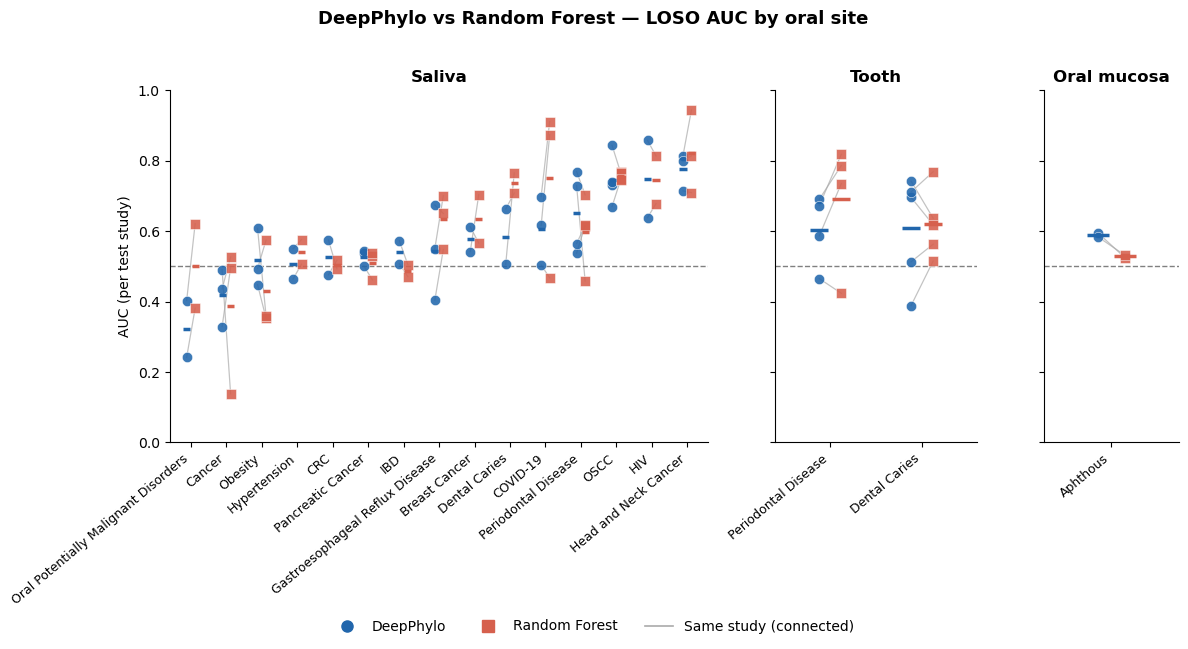

In [20]:
sites = {
    'Saliva':       ('loso_auc_all_diseases_saliva.csv',
                     'rf_loso_auc_all_diseases_saliva.csv'),
    'Tooth':        ('loso_auc_all_diseases_tooth.csv',
                     'rf_loso_auc_all_diseases_tooth.csv'),
    'Oral mucosa':  ('loso_auc_all_diseases_oral_mucosa.csv',
                     'rf_loso_auc_all_diseases_oral_mucosa.csv'),
}

MODEL_COLORS  = {'DeepPhylo': '#2166AC', 'RF': '#D6604D'}   # blue / red-orange
MODEL_MARKERS = {'DeepPhylo': 'o',       'RF': 's'}
CONNECT_COLOR = '#AAAAAA'   # grey connecting lines

# ── PLOT ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    1, 3, figsize=(12, 6), sharey=True,
    gridspec_kw={'width_ratios': [8, 3, 2]}
)

for ax, (site, (dp_file, rf_file)) in zip(axes, sites.items()):

    dp_path = os.path.join(OUTPUT_DIR, dp_file)
    rf_path = os.path.join(OUTPUT_DIR, rf_file)

    # ── load & tag ────────────────────────────────────────────────────────────
    dp = pd.read_csv(dp_path).dropna(subset=['auc']).copy()
    rf = pd.read_csv(rf_path).dropna(subset=['auc']).copy()
    dp['model'] = 'DeepPhylo'
    rf['model'] = 'RF'

    # Normalise column name: DeepPhylo may call it 'study' instead of 'test_study'
    for df in (dp, rf):
        if 'study' in df.columns and 'test_study' not in df.columns:
            df.rename(columns={'study': 'test_study'}, inplace=True)

    combined = pd.concat([dp, rf], ignore_index=True)

    # ── disease order: by DeepPhylo median auc, keep only shared diseases ─────
    # (drop RF-only diseases such as 'Other')
    dp_median = dp.groupby('disease')['auc'].median()
    rf_diseases = set(rf['disease'])
    order = [d for d in dp_median.sort_values().index if d in rf_diseases]

    # restrict data to shared diseases only
    combined = combined[combined['disease'].isin(order)].copy()

    # ── x positions ───────────────────────────────────────────────────────────
    x_pos = {d: i for i, d in enumerate(order)}

    # ── jitter so the two models don't overlap perfectly ──────────────────────
    jitter = {'DeepPhylo': -0.12, 'RF': +0.12}

    # ── draw connecting lines first (so dots appear on top) ──────────────────
    for disease in order:
        dp_d = dp[dp.disease == disease].set_index('test_study')['auc']
        rf_d = rf[rf.disease == disease].set_index('test_study')['auc']
        shared_studies = dp_d.index.intersection(rf_d.index)
        xd = x_pos[disease]
        for study in shared_studies:
            ax.plot(
                [xd + jitter['DeepPhylo'], xd + jitter['RF']],
                [dp_d[study],              rf_d[study]],
                color=CONNECT_COLOR, lw=0.9, zorder=1, alpha=0.7
            )

    # ── scatter dots ─────────────────────────────────────────────────────────
    for model in ('DeepPhylo', 'RF'):
        sub = combined[combined.model == model]
        xs = [x_pos[d] + jitter[model] for d in sub['disease']]
        ax.scatter(
            xs, sub['auc'],
            color=MODEL_COLORS[model],
            marker=MODEL_MARKERS[model],
            s=55, zorder=3, alpha=0.88,
            edgecolors='white', linewidths=0.4,
            label=model
        )

    # ── mean markers ─────────────────────────────────────────────────────────
    for model in ('DeepPhylo', 'RF'):
        sub = combined[combined.model == model]
        for disease in order:
            vals = sub.loc[sub.disease == disease, 'auc']
            if len(vals):
                ax.hlines(
                    vals.mean(),
                    x_pos[disease] + jitter[model] - 0.10,
                    x_pos[disease] + jitter[model] + 0.10,
                    colors=MODEL_COLORS[model],
                    linewidths=2.5, zorder=4
                )

    # ── axes decoration ───────────────────────────────────────────────────────
    ax.axhline(0.5, ls='--', c='grey', lw=1)
    ax.set_title(site, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('AUC (per test study)' if ax == axes[0] else '')
    ax.set_ylim(0, 1)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=40, ha='right', fontsize=9)
    ax.set_xlim(-0.6, len(order) - 0.4)
    ax.spines[['top', 'right']].set_visible(False)

# ── shared legend ─────────────────────────────────────────────────────────────
handles = [
    mlines.Line2D([], [], color=MODEL_COLORS['DeepPhylo'],
                  marker='o', linestyle='None', markersize=8, label='DeepPhylo'),
    mlines.Line2D([], [], color=MODEL_COLORS['RF'],
                  marker='s', linestyle='None', markersize=8, label='Random Forest'),
    mlines.Line2D([], [], color=CONNECT_COLOR,
                  linestyle='-', linewidth=1.2, label='Same study (connected)'),
]
fig.legend(handles=handles, loc='lower center', ncol=3,
           frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.04))

plt.suptitle('DeepPhylo vs Random Forest — LOSO AUC by oral site',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Oral and gut paired project

# Part 2 — Paired oral–gut projects

These studies sampled **both oral and gut sites from the same cohorts**, which lets us ask a
different question: for a given disease, is the oral or the gut microbiome more predictive?

## Load the paired dataset and apply quality control

We load the paired `.biom` table and metadata and apply the same QC as before (drop rare OTUs,
drop low-depth samples, re-sync metadata), then remove samples with missing or `"Other"` labels.

In [21]:
table = biom.load_table("../../data/oral-gut-pair-v2-qc/biom_oral_gut_pair_v2_qc.biom")
metadata = pd.read_csv("../../data/oral-gut-pair-v2-qc/metadata_oral_gut_pair_v2_merge_qc.csv", low_memory=False)
sid = metadata.sample_id.values
table.filter(sid, axis="sample")
table.remove_empty()
fid = table.ids(axis="observation")
prevalence = table.nonzero_counts(axis="observation")
table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
table.remove_empty()
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [22]:
table

2324 x 7017 <class 'biom.table.Table'> with 765823 nonzero entries (4% dense)

In [23]:
metadata = metadata.loc[metadata.status_cleaned.notna()]
metadata = metadata.loc[metadata.status_cleaned != "Other"]

In [24]:
metadata.head()

,pair_id,pair_time_point,pair_bioproject,pair_type,pair_sample_number,pair_subject_number,bioproject,sample_id,subject_id,age,...,sex_cleaned,platform_cleaned,sequencing_region_cleaned,country_cleaned,continent_group,site_cleaned,site_group_cleaned,disease_study_cleaned,status_cleaned,is_time_series_cleaned
0,PRJEB1799_FS_10,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261872,FS_10,35.0,...,M,Illumina GAIIx,V2,United States,North America,feces,Gut,No,HC,no
1,PRJEB1799_FS_37,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261877,FS_37,33.0,...,M,Illumina GAIIx,V2,United States,North America,feces,Gut,No,HC,no
2,PRJEB1799_FS_10,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261880,FS_10,35.0,...,M,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no
3,PRJEB1799_FS_28,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261883,FS_28,46.0,...,M,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no
4,PRJEB1799_FS_141,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261887,FS_141,29.0,...,M,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no


In [25]:
metadata.status_cleaned.unique()

array(['HC', 'Atopic Dermatitis', 'Cardiovascular Disease', 'Lung Cancer',
       'Preterm', 'Periodontal Disease', "Parkinson's Disease",
       'COVID-19', "Alzheimer's Disease", 'Axial Spondyloarthritis',
       'HIV', 'ICU', 'Hypertension'], dtype=object)

## Keep sufficiently-sized study × site × status groups

We count samples per (project, body site, disease status) and keep only groups with **more than
10 samples**, then collect the surviving project IDs. Later we require a project to have all
**four** expected groups present (both sites × both HC/disease) before evaluating it, so the
oral-vs-gut comparison is always made on the same cohort.

In [26]:
md_summary = pd.DataFrame(metadata.groupby(["pair_bioproject", "site_group_cleaned", "status_cleaned"])["sample_id"].count())
md_summary = md_summary.loc[md_summary.sample_id > 10]

In [27]:
project_id = np.unique([i[0] for i in md_summary.index.values])

In [28]:
project_id

array(['PRJDB9093', 'PRJEB11425', 'PRJEB1799', 'PRJEB19825', 'PRJEB22984',
       'PRJEB23853', 'PRJEB24929', 'PRJEB25569', 'PRJEB25916',
       'PRJEB27304', 'PRJEB28088', 'PRJEB30836', 'PRJEB39420',
       'PRJEB39436', 'PRJEB42056', 'PRJEB6518', 'PRJNA281060',
       'PRJNA326866', 'PRJNA420339', 'PRJNA471556', 'PRJNA503194',
       'PRJNA545251', 'PRJNA595346', 'PRJNA687361', 'PRJNA742875',
       'PRJNA753008', 'PRJNA756623', 'PRJNA764503', 'PRJNA767939',
       'PRJNA778070', 'PRJNA799190', 'PRJNA851957', 'PRJNA865362',
       'qiita_11404'], dtype='<U11')

## DeepPhylo: within-study 5-fold cross-validation

Here the task is disease (any non-HC status) vs. HC, evaluated **separately for the gut and oral
samples** of each qualifying paired project. Because each project is analysed on its own, we use
**stratified 5-fold cross-validation** within the project rather than leave-one-study-out.

We first load the shared OTU order, phylogenetic embedding, and relative-abundance matrix, then
loop over projects and sites: build the binary label, run 5-fold stratified CV, train DeepPhylo
on each fold (with an internal validation split for early stopping), and record the per-fold test
AUC. Folds that cannot support both classes are skipped. We save both the per-fold AUCs and a
per-(study, site) mean/std summary.

In [29]:
# ── Load precomputed embedding + OTU order from disk ─────────────────────────
otu_ids        = np.load(f"{OUTPUT_DIR}/otu_ids.npy", allow_pickle=True).tolist()
phy_emb_global = np.load(f"{OUTPUT_DIR}/phy_emb_global_hs{DP_HIDDEN_SIZE}.npy")

# ── Compute abundance in-notebook (not the bottleneck), aligned to saved otu_ids ─
abund_all = (table.norm(axis='sample', inplace=False)
             .to_dataframe(dense=True).T
             .reindex(columns=otu_ids, fill_value=0)
             .astype(np.float32))
print(f"OTUs={len(otu_ids)}  emb={phy_emb_global.shape}  abund={abund_all.shape}")

OTUs=2670  emb=(2670, 80)  abund=(7017, 2670)


In [30]:
N_SPLITS = 5
all_records = []
for i in project_id:
    if md_summary.loc[i].shape[0] != 4:
        continue
    for site in ["Gut", "Oral"]:
        metadata_pick = metadata.loc[metadata.pair_bioproject == i].copy()
        metadata_pick = metadata_pick.loc[metadata_pick.site_group_cleaned == site].copy()
        metadata_pick["label"] = (metadata_pick["status_cleaned"] != "HC").astype(int)
        sid = metadata_pick.sample_id.values
        y   = metadata_pick["label"].values.astype(int)
        X   = abund_all.loc[sid].values.astype(np.float32)
        cls_count = np.bincount(y, minlength=2)
        if len(np.unique(y)) < 2 or cls_count.min() < N_SPLITS:
            print(f"[SKIP] study {i} / {site}: "
                  f"n={len(y)} pos={int(y.sum())} cannot run {N_SPLITS}-fold stratified CV")
            all_records.append({'study': i, 'site': site, 'fold': np.nan,
                                'n_train': np.nan, 'n_test': len(y),
                                'n_test_pos': int(y.sum()), 'auc': np.nan})
            continue
        skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
        for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), start=1):
            X_all,  Y_all  = X[tr_idx], y[tr_idx].astype(np.float32)
            X_test, Y_test = X[te_idx], y[te_idx].astype(np.float32)
            # Test fold not both-class -> AUC undefined, record NaN
            if len(np.unique(Y_test)) < 2:
                print(f"  study {i}/{site} fold{fold}: test fold not both-class, skip")
                all_records.append({'study': i, 'site': site, 'fold': fold,
                                    'n_train': len(X_all), 'n_test': len(X_test),
                                    'n_test_pos': int(Y_test.sum()), 'auc': np.nan})
                continue
            # --- internal train/val split within the train fold, for early stopping ---
            can_strat = np.bincount(Y_all.astype(int)).min() >= 2
            X_tr, X_val, Y_tr, Y_val = train_test_split(
                X_all, Y_all, test_size=DP_VAL_FRAC, random_state=42,
                stratify=Y_all if can_strat else None)
            model = train_deepphylo(X_tr, Y_tr, X_val, Y_val, phy_emb_global)
            pred  = predict_proba(model, X_test, phy_emb_global)
            auc   = roc_auc_score(Y_test, pred)
            print(f"  study {i}/{site} fold{fold}: "
                  f"n_train={len(X_all)} n_test={len(X_test)} "
                  f"pos={int(Y_test.sum())} AUC={auc:.3f}")
            all_records.append({'study': i, 'site': site, 'fold': fold,
                                'n_train': len(X_all), 'n_test': len(X_test),
                                'n_test_pos': int(Y_test.sum()), 'auc': round(auc, 4)})
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
# --- aggregate and save ---
df_all = pd.DataFrame(all_records)
df_all.to_csv(f"{OUTPUT_DIR}/cv5_auc_by_study_site.csv", index=False)
# mean / std of the 5 folds per study x site
summary = (df_all.dropna(subset=['auc'])
                 .groupby(['study', 'site'])['auc']
                 .agg(['mean', 'std', 'count'])
                 .reset_index())
summary.to_csv(f"{OUTPUT_DIR}/cv5_auc_summary.csv", index=False)
print(summary)

  study PRJDB9093/Gut fold1: n_train=52 n_test=13 pos=10 AUC=1.000


  study PRJDB9093/Gut fold2: n_train=52 n_test=13 pos=10 AUC=1.000


  study PRJDB9093/Gut fold3: n_train=52 n_test=13 pos=10 AUC=0.967


  study PRJDB9093/Gut fold4: n_train=52 n_test=13 pos=11 AUC=1.000


  study PRJDB9093/Gut fold5: n_train=52 n_test=13 pos=11 AUC=1.000


...

  study PRJNA767939/Oral fold1: n_train=28 n_test=8 pos=5 AUC=1.000


  study PRJNA767939/Oral fold2: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold3: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold4: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold5: n_train=29 n_test=7 pos=4 AUC=1.000
          study  site     mean       std  count
0     PRJDB9093   Gut  0.99334  0.014892      5
1     PRJDB9093  Oral  0.93756  0.071354      5
2    PRJEB23853   Gut  0.96894  0.033297      5
3    PRJEB23853  Oral  1.00000  0.000000      5
4    PRJEB25569   Gut  0.97500  0.034233      5
5    PRJEB25569  Oral  0.79354  0.158282      5
6   PRJNA742875   Gut  0.67544  0.093584      5
7   PRJNA742875  Oral  0.64044  0.138718      5
8   PRJNA764503   Gut  0.41786  0.275087      5
9   PRJNA764503  Oral  0.40120  0.130912      5
10  PRJNA767939   Gut  0.93334  0.108652      5
11  PRJNA767939  Oral  1.00000  0.000000      5


### RF

## Random Forest baseline (same 5-fold protocol)

The same within-study 5-fold cross-validation, now with a class-weighted Random Forest instead
of DeepPhylo. Splits and AUC computation match the DeepPhylo run exactly, so the two are
comparable per fold, per study, and per site. Results go to separate `rf_*` CSV files.

In [31]:
N_SPLITS = 5
all_records = []
for i in project_id:
    if md_summary.loc[i].shape[0] != 4:
        continue
    for site in ["Gut", "Oral"]:
        metadata_pick = metadata.loc[metadata.pair_bioproject == i].copy()
        metadata_pick = metadata_pick.loc[metadata_pick.site_group_cleaned == site].copy()
        metadata_pick["label"] = (metadata_pick["status_cleaned"] != "HC").astype(int)
        sid = metadata_pick.sample_id.values
        y   = metadata_pick["label"].values.astype(int)
        X   = abund_all.loc[sid].values.astype(np.float32)
        cls_count = np.bincount(y, minlength=2)
        if len(np.unique(y)) < 2 or cls_count.min() < N_SPLITS:
            print(f"[SKIP] study {i} / {site}: "
                  f"n={len(y)} pos={int(y.sum())} cannot run {N_SPLITS}-fold stratified CV")
            all_records.append({'study': i, 'site': site, 'fold': np.nan,
                                'n_train': np.nan, 'n_test': len(y),
                                'n_test_pos': int(y.sum()), 'auc': np.nan})
            continue
        skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
        for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), start=1):
            X_train, Y_train = X[tr_idx], y[tr_idx].astype(int)
            X_test,  Y_test  = X[te_idx], y[te_idx].astype(int)
            
            # Test fold not both-class -> AUC undefined, record NaN
            if len(np.unique(Y_test)) < 2:
                print(f"  study {i}/{site} fold{fold}: test fold not both-class, skip")
                all_records.append({'study': i, 'site': site, 'fold': fold,
                                    'n_train': len(X_train), 'n_test': len(X_test),
                                    'n_test_pos': int(Y_test.sum()), 'auc': np.nan})
                continue
            
            # --- Train Random Forest (no validation split needed) ---
            rf_model = RandomForestClassifier(n_estimators=100, random_state=42,
                                              n_jobs=-1, class_weight='balanced')
            rf_model.fit(X_train, Y_train)
            
            # --- Predict and calculate AUC ---
            pred = rf_model.predict_proba(X_test)[:, 1]
            auc  = roc_auc_score(Y_test, pred)
            print(f"  study {i}/{site} fold{fold}: "
                  f"n_train={len(X_train)} n_test={len(X_test)} "
                  f"pos={int(Y_test.sum())} AUC={auc:.3f}")
            
            all_records.append({'study': i, 'site': site, 'fold': fold,
                                'n_train': len(X_train), 'n_test': len(X_test),
                                'n_test_pos': int(Y_test.sum()), 'auc': round(auc, 4)})

# --- aggregate and save ---
df_all = pd.DataFrame(all_records)
df_all.to_csv(f"{OUTPUT_DIR}/rf_cv5_auc_by_study_site.csv", index=False)

# mean / std of the 5 folds per study x site
summary = (df_all.dropna(subset=['auc'])
                 .groupby(['study', 'site'])['auc']
                 .agg(['mean', 'std', 'count'])
                 .reset_index())
summary.to_csv(f"{OUTPUT_DIR}/rf_cv5_auc_summary.csv", index=False)
print(summary)

  study PRJDB9093/Gut fold1: n_train=52 n_test=13 pos=10 AUC=1.000


  study PRJDB9093/Gut fold2: n_train=52 n_test=13 pos=10 AUC=1.000


  study PRJDB9093/Gut fold3: n_train=52 n_test=13 pos=10 AUC=1.000


  study PRJDB9093/Gut fold4: n_train=52 n_test=13 pos=11 AUC=1.000


  study PRJDB9093/Gut fold5: n_train=52 n_test=13 pos=11 AUC=1.000


...

  study PRJNA767939/Oral fold1: n_train=28 n_test=8 pos=5 AUC=1.000


  study PRJNA767939/Oral fold2: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold3: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold4: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold5: n_train=29 n_test=7 pos=4 AUC=1.000
          study  site     mean       std  count
0     PRJDB9093   Gut  1.00000  0.000000      5
1     PRJDB9093  Oral  0.97334  0.043460      5
2    PRJEB23853   Gut  0.99542  0.004738      5
3    PRJEB23853  Oral  1.00000  0.000000      5
4    PRJEB25569   Gut  0.98542  0.020307      5
5    PRJEB25569  Oral  0.76952  0.111635      5
6   PRJNA742875   Gut  0.67944  0.129287      5
7   PRJNA742875  Oral  0.59956  0.099142      5
8   PRJNA764503   Gut  0.77680  0.168911      5
9   PRJNA764503  Oral  0.51428  0.108517      5
10  PRJNA767939   Gut  0.92834  0.085295      5
11  PRJNA767939  Oral  1.00000  0.000000      5


## Attach disease labels to the results

We load both models' per-fold AUC tables and map each project ID to its disease name (the single
non-HC status in that project), so the final figure can be grouped by disease.

In [32]:
df_all_dp = pd.read_csv(f"{OUTPUT_DIR}/cv5_auc_by_study_site.csv")
pro_disease = metadata.loc[metadata.status_cleaned != "HC"].drop_duplicates(subset='bioproject')
pro_disease_dict = dict(zip(pro_disease.bioproject.values, pro_disease.status_cleaned.values))
df_all_dp["disease"] = [pro_disease_dict[i] for i in df_all_dp.study.values]

df_all_rf = pd.read_csv(f"{OUTPUT_DIR}/rf_cv5_auc_by_study_site.csv")
pro_disease = metadata.loc[metadata.status_cleaned != "HC"].drop_duplicates(subset='bioproject')
pro_disease_dict = dict(zip(pro_disease.bioproject.values, pro_disease.status_cleaned.values))
df_all_rf["disease"] = [pro_disease_dict[i] for i in df_all_rf.study.values]

## Final comparison: per-disease boxplots

One panel per disease. Within each panel the x-axis is the study and the boxes are grouped by
**site × model** (Gut/Oral × DeepPhylo/RF): colour encodes the site and shade encodes the model
(dark = DeepPhylo, light = RF). Individual fold AUCs are overlaid as jittered points, and the
dashed line marks chance (0.5). This lets us read off, for each disease and study, whether
DeepPhylo improves on Random Forest and whether the oral or gut site carries more signal.

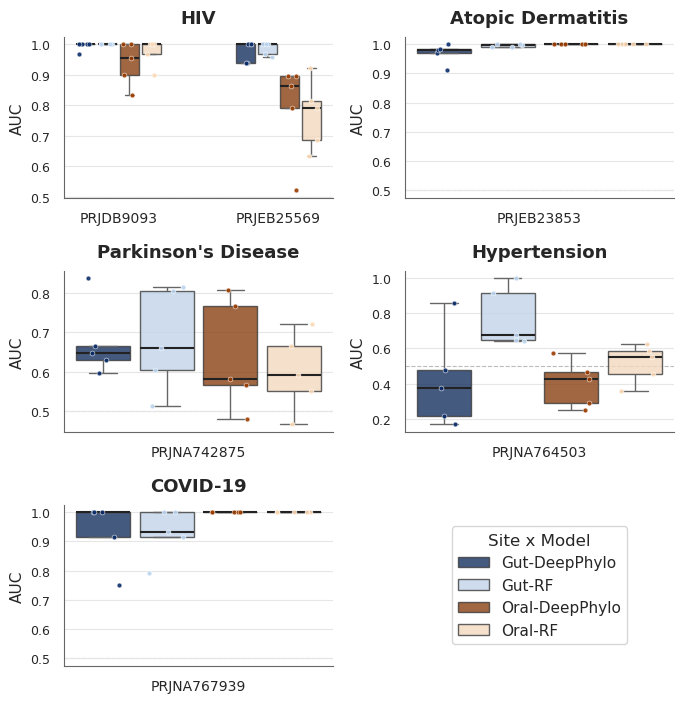

In [33]:
"""
Per-disease panels comparing DeepPhylo vs RF.
x = study, boxes grouped by (site x model):
    hue color  -> site  (Gut / Oral)
    hue shade  -> model (DeepPhylo = dark, RF = light)
"""
import math
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# ── INPUT ────────────────────────────────────────────────────────────────────
dp = df_all_dp.copy(); dp["model"] = "DeepPhylo"
rf = df_all_rf.copy(); rf["model"] = "RF"
combined = pd.concat([dp, rf], ignore_index=True)
combined["site_model"] = combined["site"] + "-" + combined["model"]

# ── Global style ──────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "font.family":     "DejaVu Sans",
    "axes.titlesize":  13, "axes.titleweight": "bold",
    "axes.labelsize":  11, "axes.edgecolor":   "#666666",
    "axes.linewidth":  0.8,
    "grid.color":      "#E6E6E6", "grid.linewidth": 0.8,
    "xtick.labelsize": 10, "ytick.labelsize":  9,
})

hue_order = ["Gut-DeepPhylo", "Gut-RF", "Oral-DeepPhylo", "Oral-RF"]
palette = {
    "Gut-DeepPhylo":  "#0B2D6B",
    "Gut-RF":         "#BBD4F0",
    "Oral-DeepPhylo": "#9C3D00",
    "Oral-RF":        "#FBD9B5",
}

# ── Spacing parameters ────────────────────────────────────────────────────────
BOX_WIDTH = 0.55
BOX_GAP   = 0.15
N_HUES    = len(hue_order)
SLOT_W    = BOX_WIDTH / N_HUES          # width allocated per hue group
# jitter half-range: points fill ~70% of the actual box face (after gap)
HALF_JIT  = SLOT_W * (1 - BOX_GAP) * 0.35

diseases = combined["disease"].unique()
n = len(diseases); ncols = 2; nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 3.5, nrows * 2.4),
                         squeeze=False)
axes = axes.flatten()

handles, labels = None, None
rng = np.random.default_rng(seed=0)   # fixed seed for reproducible jitter

for i, disease in enumerate(diseases):
    ax = axes[i]
    sub = combined[combined["disease"] == disease]

    # Explicit study order so boxplot and scatter share the same x mapping
    study_order = list(sub["study"].unique())
    study_to_x  = {s: j for j, s in enumerate(study_order)}

    # ── Box plot ──────────────────────────────────────────────────────────────
    sns.boxplot(
        data=sub, x="study", y="auc",
        hue="site_model", hue_order=hue_order,
        order=study_order,          # anchor x-axis order
        ax=ax,
        width=BOX_WIDTH,
        gap=BOX_GAP,
        showfliers=False,
        palette=palette,
        linewidth=1.0,
        boxprops=dict(alpha=0.8, edgecolor="#3a3a3a"),
        medianprops=dict(color="#222222", linewidth=1.5),
        whiskerprops=dict(color="#666666", linewidth=1.0),
        capprops=dict(color="#666666", linewidth=1.0),
    )

    # ── Manual scatter: positions computed from the same geometry as boxplot ──
    # Box centers: x_tick + (-BOX_WIDTH/2 + (h + 0.5) * SLOT_W)
    # gap only shrinks box width; it does NOT shift the center, so no gap term here
    for h_idx, hue_key in enumerate(hue_order):
        pts = sub[sub["site_model"] == hue_key]
        if pts.empty:
            continue
        x_center = -BOX_WIDTH / 2 + (h_idx + 0.5) * SLOT_W
        x_pos = (pts["study"].map(study_to_x).values.astype(float)
                 + x_center
                 + rng.uniform(-HALF_JIT, HALF_JIT, len(pts)))
        ax.scatter(x_pos, pts["auc"].values,
                   color=palette[hue_key],
                   s=3.5 ** 2, alpha=0.9,
                   edgecolors="white", linewidths=0.4,
                   zorder=3)

    ax.set_title(str(disease), pad=10)
    ax.set_xlabel(""); ax.set_ylabel("AUC")
    ax.grid(axis="x", visible=False)
    ax.axhline(0.5, color="#BBBBBB", ls="--", lw=0.8, zorder=0)
    sns.despine(ax=ax)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    if ax.get_legend() is not None:
        ax.get_legend().remove()

# ── Shared legend ─────────────────────────────────────────────────────────────
for j in range(n, len(axes)):
    axes[j].axis("off")

if n < len(axes):
    axes[n].legend(handles, labels, title="Site x Model", loc="center",
                   frameon=True, fontsize=11, title_fontsize=12, markerscale=1.3)
else:
    fig.legend(handles, labels, title="Site x Model", loc="upper right",
               frameon=True, fontsize=10, title_fontsize=11)

fig.tight_layout()
plt.show()